# Figure 2B–E


In [1]:
from pathlib import Path
import sys
base_path = next(
    p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
    if (p / "CODE").is_dir() and (p / "DATA").is_dir()
)
sys.path.insert(0, str(Path(base_path) / 'CODE'))


In [2]:
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import os

In [3]:
output_dir = f"{base_path}/FIGURES/main/Fig_2"
os.makedirs(output_dir, exist_ok=True)

## 2B: MRS and H models

In [4]:
# Data parameters
measures = ['GABA', 'Glx', 'EIB']
field = 'Hursts'
drop_rests = [False]
only_MRS_parcels = [True]

lmm_results_path = f'{base_path}/RESULTS/replication_dataset/models'
output_path = f'{base_path}/FIGURES/main/Fig_2'
os.makedirs(output_path, exist_ok=True)

# Plotting parameters
figsize = (15, 8) # (7, 6) (14, 8)
TITLE_FS = 16      
LABEL_FS = 32       
TICK_FS  = 35     
MARKERS = 100
LINE = 4
FONT_W   = 'bold'
AX_GREY  = "#424242"

task_colors = {
    'Rest':  '#ff5e69',
    '0Back': '#86ab00',
    '1Back': '#03b6ce',
    '2Back': '#8491ff'
}

In [5]:
from utils.model_helpers import get_task_slope_intercept

# helper functions
point_kw = dict(s=MARKERS, alpha=0.25, linewidths=0)

def plot_measure_vs_Hurst(ax, res, df, measure, field, tasks):

    df = df.copy()
    df["Task"] = df["Task"].astype("category")
    ref_task = df["Task"].cat.categories[0]

    x_all = df[measure].to_numpy()
    xmin, xmax = np.nanmin(x_all), np.nanmax(x_all)
    xpad = 0.02 * (xmax - xmin if xmax > xmin else 1.0)
    xg = np.linspace(xmin, xmax, 200)

    y_min_global = np.inf
    y_max_global = -np.inf

    # CI
    params = res.params
    cov    = res.cov_params()
    names  = params.index

    idx_intercept = names.get_loc("Intercept")
    idx_measure  = names.get_loc(measure)

    for task in tasks:
        df_t = df[df["Task"] == task]
        if df_t.empty:
            continue

        x = df_t[measure].to_numpy()
        y = df_t[field].to_numpy()
        c = task_colors[task]

        # scatter
        ax.scatter(x, y, color=c, label=task, **point_kw)

        # line
        b0, b1 = get_task_slope_intercept(res, task, ref_task, measure)
        yg = b0 + b1 * xg
        ax.plot(xg, yg, color=c, lw=LINE)


        task_param_name = f"Task[T.{task}]"
        idx_task = names.get_loc(task_param_name) if task_param_name in names else None

        inter_names = [
            f"{measure}:Task[T.{task}]",
            f"Task[T.{task}]:{measure}"
        ]
        idx_int = None
        for nm in inter_names:
            if nm in names:
                idx_int = names.get_loc(nm)
                break

        se = np.zeros_like(xg)
        for ii, x_val in enumerate(xg):
            L = np.zeros(len(params), dtype=float)

            L[idx_intercept] = 1.0
            L[idx_measure]       = x_val

            if task != ref_task and idx_task is not None:
                L[idx_task] += 1.0
            if task != ref_task and idx_int is not None:
                L[idx_int]  += x_val

            var_y = float(L @ cov @ L)
            if var_y < 0:
                var_y = 0.0
            se[ii] = np.sqrt(var_y)

        ci_hi = yg + 1.96 * se
        ci_lo = yg - 1.96 * se

        ax.fill_between(xg, ci_lo, ci_hi, color=c, alpha=0.15, linewidth=0)

        y_min_local = np.nanmin([y.min(), yg.min(), ci_lo.min()])
        y_max_local = np.nanmax([y.max(), yg.max(), ci_hi.max()])
        y_min_global = min(y_min_global, y_min_local)
        y_max_global = max(y_max_global, y_max_local)

    yrange = y_max_global - y_min_global if y_max_global > y_min_global else 1.0
    pad_y = 0.08 * yrange

    ax.set_xlim(xmin - xpad, xmax + xpad)
    if field in ["Hurst", "Hursts"]:
        ax.set_yticks([0.5, 1, 1.5, 2.0])
    ax.set_ylim(y_min_global - pad_y, y_max_global + pad_y)

    if field in ["Hurst", "Hursts"]:
        if measure == "EIB":
            ax.set_xticks([3, 4, 5, 6])
    #     elif measure == "GABA":
    #         ax.set_xticks([2, 3])
    #     elif measure == "Glx":
    #         ax.set_xticks([5, 6, 7, 8, 9, 10, 11, 12])
    #     else:
    #         ax.set_xticks([2, 3])

    if measure == "EIB":
        measure_label = "Glx/GABA+"
    else:
        measure_label = measure
    ax.set_xlabel(measure_label, fontsize=LABEL_FS, fontweight=FONT_W, color='black')
    lab = "H" if field in ["Hurst", "Hursts"] else field
    ax.set_ylabel(lab, fontsize=LABEL_FS, fontweight=FONT_W, color='black')

    ax.tick_params(axis='both', labelsize=TICK_FS)
    for spine in ax.spines.values():
        spine.set_color(AX_GREY)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

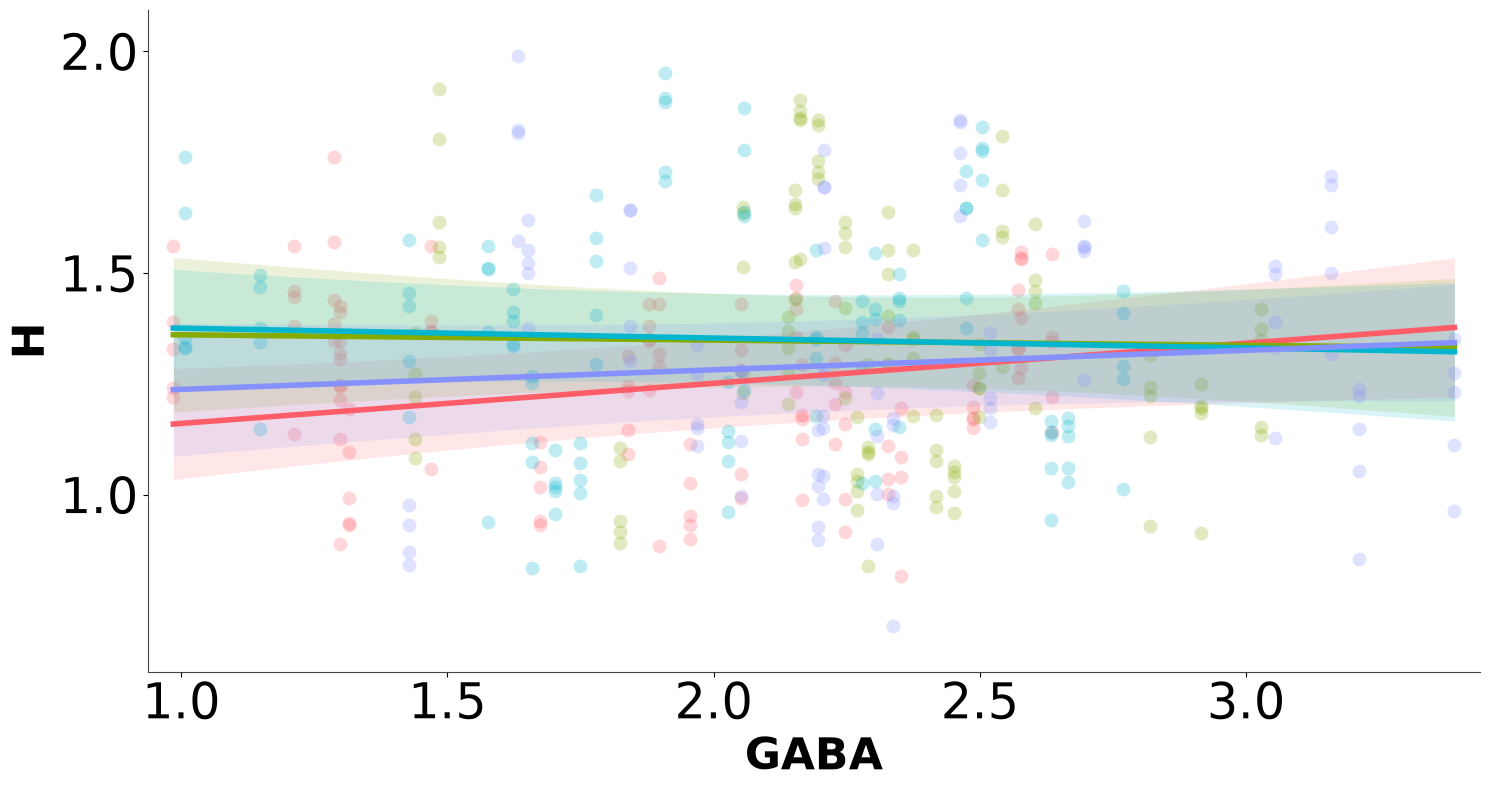

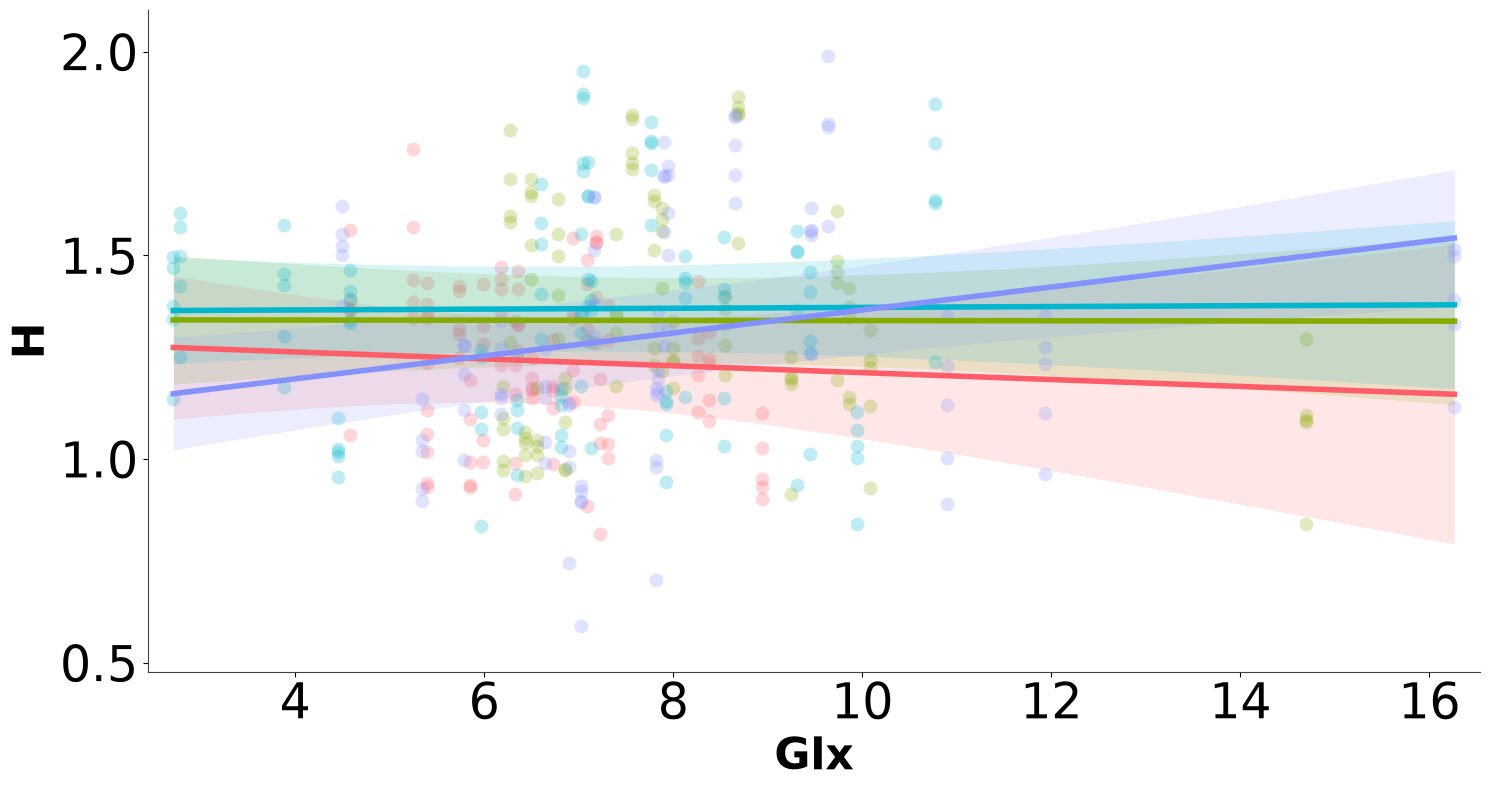

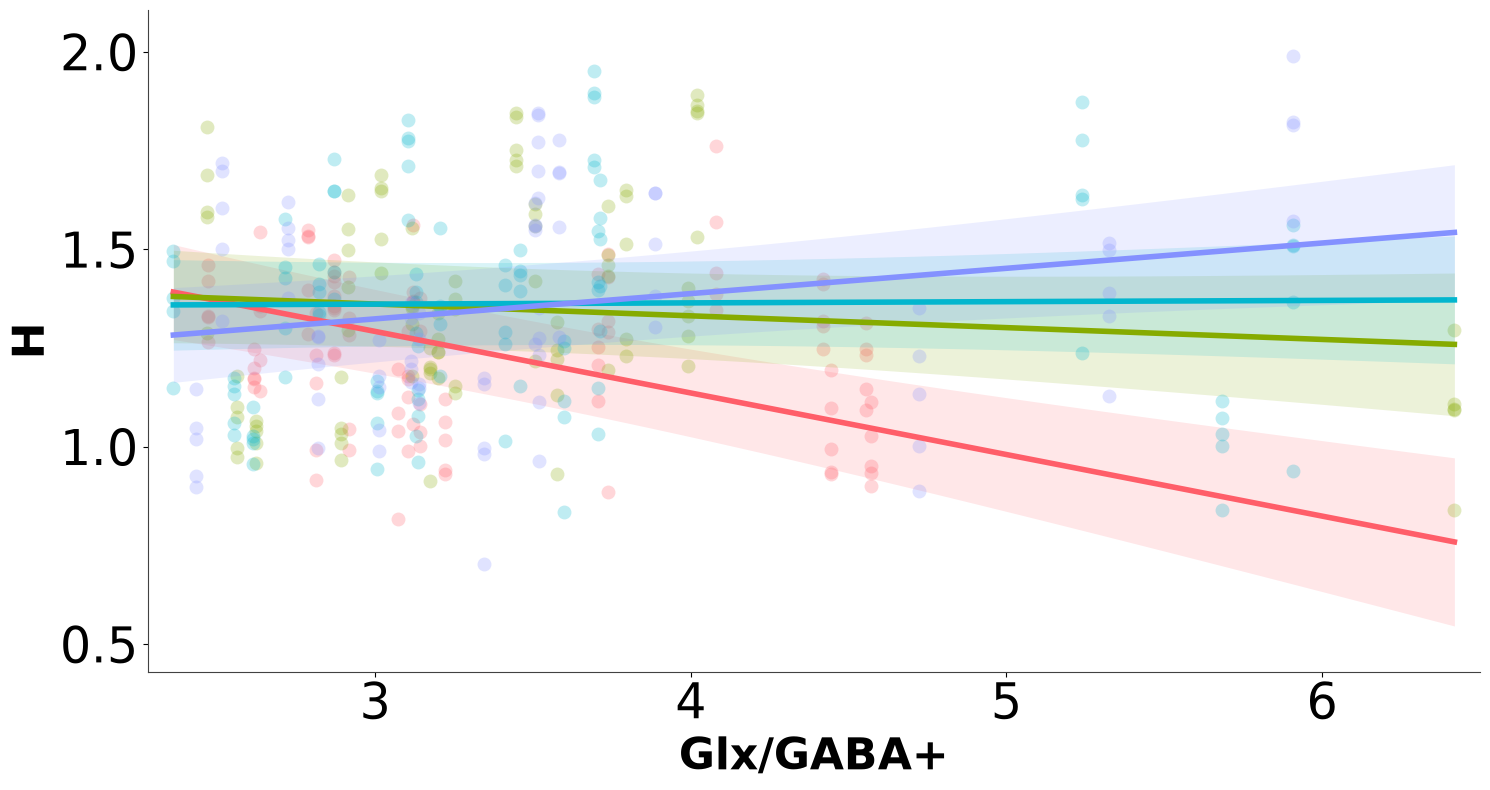

In [6]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from types import SimpleNamespace

lmm_results_path = os.path.join(
    base_path, "RESULTS", "replication_dataset", "models"
)

tasks = ["Rest", "0Back", "1Back", "2Back"]

rename_map = {"(Intercept)": "Intercept"}

for measure in measures:

    prefix = f"lmm_{measure}_{field}_full_task"

    df_path = os.path.join(lmm_results_path, f"{prefix}_df.csv")
    fixef_path = os.path.join(lmm_results_path, f"{prefix}_fixef.csv")
    vcov_path = os.path.join(lmm_results_path, f"{prefix}_vcov.csv")

    df = pd.read_csv(df_path)
    fixef_df = pd.read_csv(fixef_path)
    vcov_df = pd.read_csv(vcov_path)

    df["Task"] = pd.Categorical(
        df["Task"],
        categories=tasks,
        ordered=True
    )

    # Convert R coefficient names to Python convention.
    term_map = rename_map.copy()

    for task in tasks:
        if task == "Rest":
            continue

        term_map[f"Task{task}"] = f"Task[T.{task}]"
        term_map[f"{measure}:Task{task}"] = (
            f"{measure}:Task[T.{task}]"
        )
        term_map[f"Task{task}:{measure}"] = (
            f"Task[T.{task}]:{measure}"
        )

    fixef_df["Term"] = fixef_df["Term"].replace(term_map)
    vcov_df["Term"] = vcov_df["Term"].replace(term_map)
    vcov_df = vcov_df.rename(columns=term_map)

    params = fixef_df.set_index("Term")["Estimate"]

    cov = vcov_df.set_index("Term")
    cov = cov.loc[params.index, params.index]

    res = SimpleNamespace(
        params=params,
        cov_params=lambda: cov
    )

    fig, ax = plt.subplots(figsize=figsize)

    plot_measure_vs_Hurst(
        ax, res, df, measure, field, tasks
    )

    plt.tight_layout()

    os.makedirs(output_path, exist_ok=True)

    save_path = os.path.join(
        output_path,
        f"measure_vs_{field}_{measure}_full_task_R.png"
    )

    fig.savefig(
        save_path,
        dpi=300,
        bbox_inches="tight"
    )


## 2C/D/E: Boxplots

In [6]:
# data parameters
data_type = "microsaccades"
data_dir = f"{base_path}/RESULTS/pupillometry/{data_type}/models/order/decimated_2s/range_1_5"

# plotting parameters
LABEL_FS = 30
TICK_FS = 30
task_colors_mri = ['#86ab00', '#03b6ce', '#8491ff']
task_colors_mrs = ['#5a7300', '#02778a', '#5a61cc']

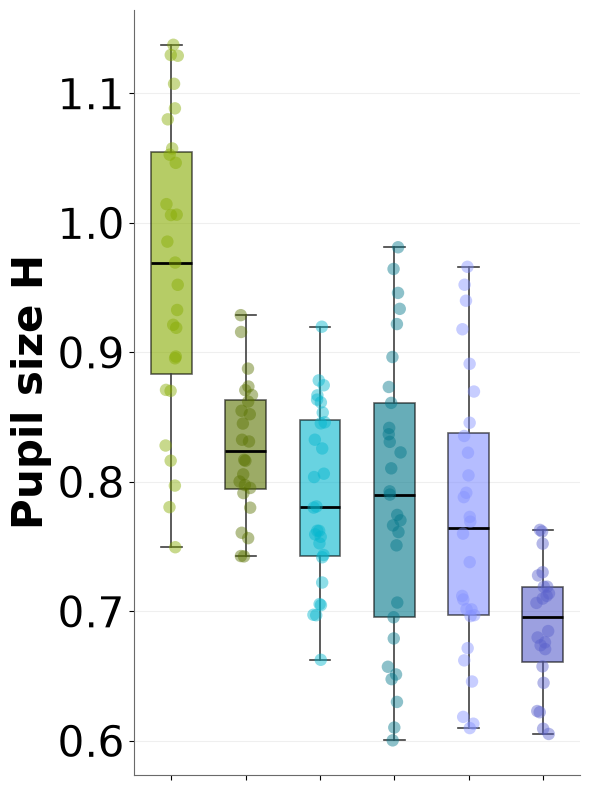

In [7]:
# load data
plot_df = pd.read_csv(f"{data_dir}/plot_df.csv")

task_order = ['0Back', '1Back', '2Back']
modality_order = ['fMRI', 'fMRS']

# prepare data for plotting
plot_df["Task"] = pd.Categorical(plot_df["Task"], categories=task_order, ordered=True)
plot_df["Modality"] = pd.Categorical(plot_df["Modality"], categories=modality_order, ordered=True)

pairs = [(t, m) for t in task_order for m in modality_order]
labels = ["" for _ in pairs]

data = []
for t, m in pairs:
    vals = plot_df.loc[
        (plot_df["Task"] == t) & (plot_df["Modality"] == m),
        "Hurst"
    ].to_numpy()
    vals = vals[np.isfinite(vals)]
    data.append(vals)

box_colors = [
    task_colors_mri[i] if j == 0 else task_colors_mrs[i]
    for i in range(len(task_order))
    for j, _ in enumerate(modality_order)
]

x = np.arange(1, len(pairs) + 1)
pos = {(t, m): x[i] for i, (t, m) in enumerate(pairs)}

# plot
ffig, ax = plt.subplots(figsize=(6, 8))

bp = ax.boxplot(
    data,
    positions=x,
    widths=0.55,
    patch_artist=True,
    showmeans=False,
    medianprops=dict(color="black", linewidth=2),
    boxprops=dict(linewidth=1.2),
    whiskerprops=dict(linewidth=1.2, color="0.25"),
    capprops=dict(linewidth=1.2, color="0.25"),
    flierprops=dict(marker='o', markersize=3, markerfacecolor='0.4', markeredgecolor='0.4', alpha=0.25),
)

for patch, c in zip(bp["boxes"], box_colors):
    patch.set_facecolor(c)
    patch.set_alpha(0.6)
    patch.set_edgecolor("k")

# scatterplot
rng = np.random.default_rng(42)

for i, (t, m) in enumerate(pairs):
    vals = plot_df.loc[
        (plot_df["Task"] == t) & (plot_df["Modality"] == m),
        ["Subject", "Hurst"]
    ].dropna()

    if len(vals) == 0:
        continue

    x0 = x[i]
    jitter = rng.uniform(-0.09, 0.09, size=len(vals))
    ax.scatter(
        np.full(len(vals), x0) + jitter,
        vals["Hurst"].to_numpy(),
        s=80,
        color=box_colors[i],
        alpha=0.45,
        edgecolors="none",
        zorder=3
    )

ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=TICK_FS)
ax.set_ylabel(f"Pupil size H", fontsize=LABEL_FS, fontweight="bold")
ax.tick_params(axis='y', labelsize=TICK_FS)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="y", alpha=0.2)

# legend
legend_elements = [
    Patch(facecolor=task_colors_mrs[0], edgecolor='k', alpha=0.8, label='0-back fMRS'),
    Patch(facecolor=task_colors_mri[0], edgecolor='k', alpha=0.8, label='0-back fMRI'),
    Patch(facecolor=task_colors_mrs[1], edgecolor='k', alpha=0.8, label='1-back fMRS'),
    Patch(facecolor=task_colors_mri[1], edgecolor='k', alpha=0.8, label='1-back fMRI'),
    Patch(facecolor=task_colors_mrs[2], edgecolor='k', alpha=0.8, label='2-back fMRS'),
    Patch(facecolor=task_colors_mri[2], edgecolor='k', alpha=0.8, label='2-back fMRI'),
]

# ax.legend(handles=legend_elements, loc='upper center', bbox_to_anchor=(0.5, -0.08),
#           ncol=2, frameon=False, fontsize=TICK_FS)

grey = "#6A6A6A"
for spine in ["bottom", "left"]:
    ax.spines[spine].set_color(grey)

plt.tight_layout()
plt.show()

ffig.savefig(f"{output_dir}/{data_type}_boxplot.png", dpi=300, bbox_inches="tight")